In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv("Life_Expectancy_Data.csv")
print('dimension du dataset df :', df.shape) #(lignes, colonnes)

df = df.dropna() #supprime les lignes avec des valeurs manquantes
print('dimension du dataset df après suppression des lignes avec valeurs manquantes :', df.shape)

df1 = df[(df.Year == 2000)]
X_pd = df1[['Life_expectancy', 'Schooling']].astype(float)
print('dimension du sous-dataset X :', X_pd.shape,
       'il reste donc', X_pd.shape[0], 'lignes pour', X_pd  .shape[1], 'variables')
# le .astype() evite l'erreur suivante : 
# La colonne Status contient du texte. Même après .replace(...) par des 0 et des 1,
# pandas conserve un dtype non numérique (object, ou str selon ta version).

y_pd =df1[['Status']].replace(['Developing', 'Developed'], [0, 1]).astype(float)
print('dimension du sous-dataset y :', y_pd.shape, 
      'il reste donc', y_pd.shape[0], 'lignes pour', y_pd.shape[1], 'variable')

dimension du dataset df : (2938, 22)
dimension du dataset df après suppression des lignes avec valeurs manquantes : (1649, 22)
dimension du sous-dataset X : (61, 2) il reste donc 61 lignes pour 2 variables
dimension du sous-dataset y : (61, 1) il reste donc 61 lignes pour 1 variable


Pour que matplotlib puisse lire X et y ils faut les convertir de DataFrame Pandas en array NumPy en utilisant ".to_numpy()"

(61, 2) (61, 1)


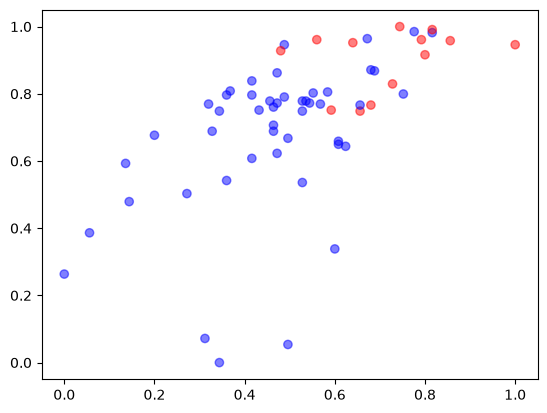

In [40]:
X = X_pd.to_numpy()
y = y_pd.to_numpy()
print(X.shape, y.shape)

X = ((X - X.min(axis=0)) / (X.max(axis=0) - X.min(axis=0)))
#axis=0 permet de normaliser par colonne (life_expectancy,schooling)
#le broadcasting de NumPy permet la soustraction (NumPy étire X.min() pour permettre X - X.min())
#ainsi on a un min et max pour chaque colonne et non un min et max commun aux 2

plt.scatter(X[:, 1], X[:, 0], c=y, cmap='bwr', alpha=0.5) 
#alpha=0.5 points transparents pour mieux visualiser les points superposés

In [4]:
def initialisation(X) :
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return W, b

In [5]:
def model(X,W, b) :
    Z = X.dot(W) + b    #opération possible grâce au broadcasting de numpy
    A = 1 / (1 + np.exp(-Z))
    return A

In [6]:
def log_loss(A, y) :
    return -1 / len(y) * np.sum(y * np.log(A) + (1-y) * np.log(1-A))

In [7]:
def gradients(A, X, y) : 
    dW = 1 / len(y) * np.dot(X.T, A - y)    #A - y donne ici une matrice
    db = 1 / len(y) * np.sum(A - y)    #np.sum(A - y) donne ici un scalaire
    return dW, db

In [8]:
def update(dW, db, W, b, lr) :    #lr pour learning rate
    W = W - lr * dW
    b = b - lr *db
    return W, b

In [16]:
def artificial_neuron(X, y, lr, n_iter) :
    W, b = initialisation(X)
    loss = []
    for i in range (n_iter) :
        A = model(X, W, b)
        loss.append(log_loss(A, y))
        dW, db = gradients(A, X, y)
        W, b = update(dW, db, W, b, lr)
    return loss, (W, b)

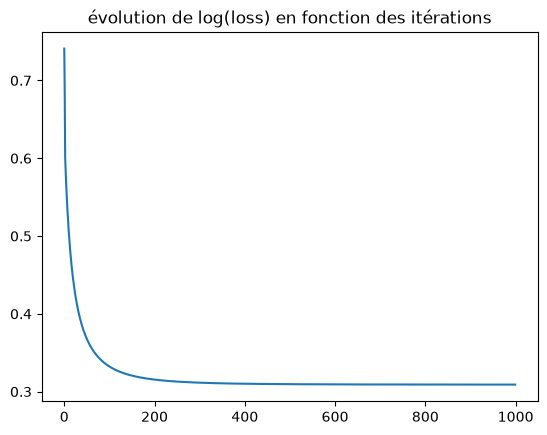

W =  [[6.63610694]
 [7.86976235]] b =  [-11.41783065]


In [41]:
n_iter = 1000
lr = 5
loss, (W, b) = artificial_neuron(X, y, lr, n_iter)
plt.title("évolution de log(loss) en fonction des itérations")
plt.plot(loss)
plt.show()
print("W = ", W, "b = ", b)

Par tatônnement on observe qu'un learning rate compris entre 0.1 et 1 est optimal. Au delà de 1, des oscillations apparaissent, preuve d'un lr trop grand.

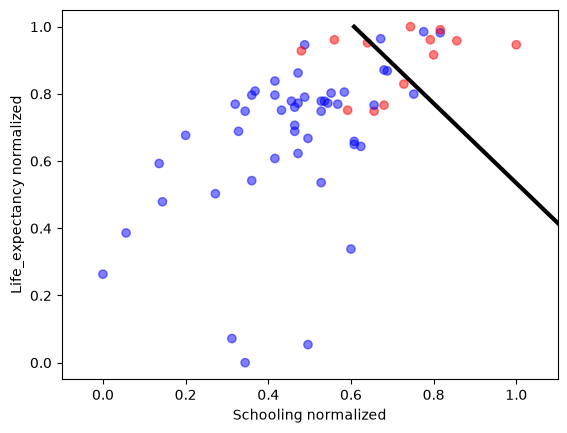

In [46]:
# La courbe de séparation est Z = W0.X0 + W1.X1 + b = 0

X0 = np.linspace(X[:,0].min(), X[:,0].max(), 100)
X1 = - (W[0] * X0 + b) / W[1]

plt.scatter(X[:, 1], X[:, 0], c=y, cmap='bwr', alpha=0.5) 
plt.plot(X1, X0, color='black', lw=3)
plt.xlabel("Schooling normalized")
plt.ylabel("Life_expectancy normalized")
plt.xlim(-0.1, 1.1)
plt.show()